# Title of your project

#### Student name(s)

Abstract of the project comes here.

# Predicting Red Wine Quality Using Machine Learning

**Student Name:** Paulo Henrique Abdala Araujo

**Course:** AIT620

**Project:** Final Exam

## Abstract

This project explores whether machine learning can be used to predict red wine quality (using physicochemical data). The experiment comprises Exploratory Data Analysis (EDA), data preprocessing and comparison of three classification algorithms namely: Logistic Regression, Decision Tree, and Random Forest. The accuracy, precision, recall and F1 score are used to evaluate performances.

## Table of Content

[Problem](#problem)   
[Data Understanding](#data_understanding)   
[Data Preparation](#data_preparation)   
[Modeling](#modeling)   
[Evaluation](#evaluation)   
[References](#references)   


## Problem

### Problem Statement

A number of physicochemical properties affect the quality of wines such as acidity, alcohol content, residual sugar and the pH. Traditionally, wine quality is assessed using sensors and a subjective sight and taste evaluation can take a significant amount of time.

This project aims to assess the use of machine learning algorithms on the prediction of the quality of red wine from its measurable chemical properties.

### Research Questions

1. Which physicochemical characteristics are most strongly associated with red wine quality?
2. Can machine learning algorithms accurately classify wines into high-quality and lower-quality categories?
3. Which classification algorithm performs best: Logistic Regression, Decision Tree, or Random Forest?

### Project Objectives

The primary goal is to create machine learning models and compare them in Python and scikit-learn.

The experiment will include:

- Exploratory Data Analysis (EDA) with tables and at least five charts.
- Data preprocessing and feature selection.
- Training three classification algorithms.
- Evaluating models using accuracy, precision, recall, and F1 score.
- Identifying the best-performing model based on F1 score.

Wines with quality scores of 7 or higher will be classified as high quality (1), while wines with scores below 7 will be classified as lower quality (0).

## Data Understanding

### Dataset Description

This project utilizes data provided by UCI for Red Wine Quality from the UCI Machine Learning Repository. The data consists of 11 physicochemical characteristics for 1,599 samples of red wine, such as acidity, alcohol, residual sugar, chlorides, density, pH.

The primary target variable (quality) is a sensory quality score. In this experiment, the target variable is a measure of the quality of the wine that will be used to classify it into class high_quality, when the score of wine is 7 or it is more, and class lower_quality in cases the score of wine is less than 7.

This dataset was chosen for real-world numerical data which would be suitable for exploratory data analysis and supervised machine learning classification.

**Dataset Source:** https://archive.ics.uci.edu/dataset/186/wine+quality

**Original Study:** Cortez et al. (2009), Modeling Wine Preferences by Data Mining from Physicochemical Properties.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [8]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDescriptive Statistics:")
display(df.describe().round(2))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Column Names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur diox

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00
mean,8.32,0.53,0.27,2.54,0.09,15.87,46.47,1.00,3.31,0.66,10.42,5.64
std,1.74,0.18,0.19,1.41,0.05,10.46,32.90,0.00,0.15,0.17,1.07,0.81
min,4.60,0.12,0.00,0.90,0.01,1.00,6.00,0.99,2.74,0.33,8.40,3.00
25%,7.10,0.39,0.09,1.90,0.07,7.00,22.00,1.00,3.21,0.55,9.50,5.00
50%,7.90,0.52,0.26,2.20,0.08,14.00,38.00,1.00,3.31,0.62,10.20,6.00
75%,9.20,0.64,0.42,2.60,0.09,21.00,62.00,1.00,3.40,0.73,11.10,6.00
max,15.90,1.58,1.00,15.50,0.61,72.00,289.00,1.00,4.01,2.00,14.90,8.00


In [9]:
print("Missing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Duplicate Rows:", df.duplicated().sum())

print("\nWine Quality Distribution:")
display(
    df["quality"]
    .value_counts()
    .sort_index()
    .to_frame("Number of Wines")
)

Missing Values:


,Missing Values
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Duplicate Rows: 240

Wine Quality Distribution:


,Number of Wines
quality,
3,10
4,53
5,681
6,638
7,199
8,18


### Initial Data Understanding Summary

The Red Whine Quality dataset is composed of 1599 observations and 12 column features: 11 are physicochemical input features with 1 being a score of wine quality.

The first analysis investigates the structure of the data set, descriptive statistics, missing values, duplicate records and distribution of scores of data quality.

The results of these findings will help preprocess the data, visualize the data and develop machine learning models.

## Data Preparation<a class="anchor" id="data_preparation"></a>


The data was reviewed for missing and duplicate data. Duplicate records were kept in case the same measurements are the same wine types.

A binary indicator was formed where quality scored 7 or above wine as a high quality (1) and the rest of the wine as a lower quality (0).

To explore the features distributions and decorrelations, and relationships with wine quality, Exploratory Data Analysis (EDA) was carried out.

In [10]:
# Create binary target
df["high_quality"] = (df["quality"] >= 7).astype(int)

# Check data
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

display(df["high_quality"].value_counts().to_frame("Count"))

Missing values: 0
Duplicate rows: 240


,Count
high_quality,
0,1382
1,217


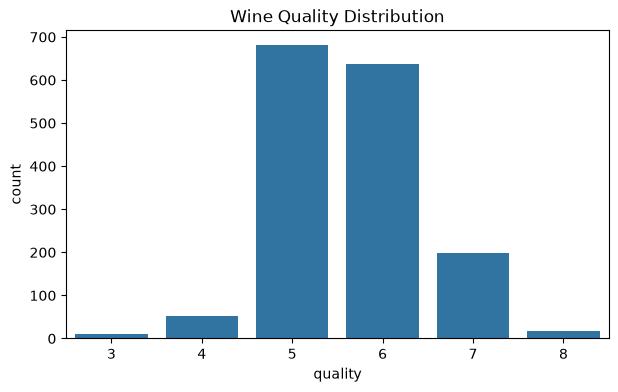

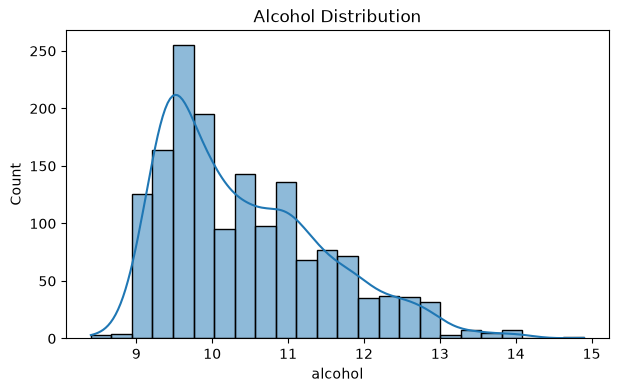

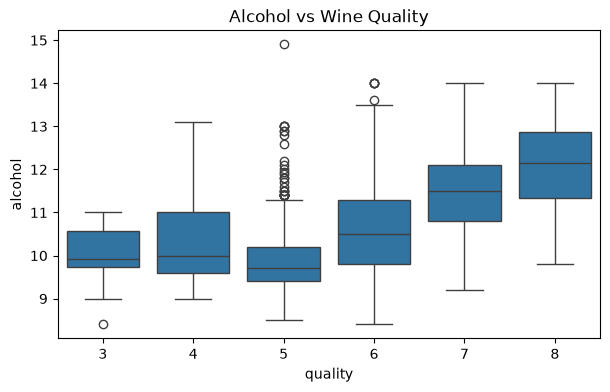

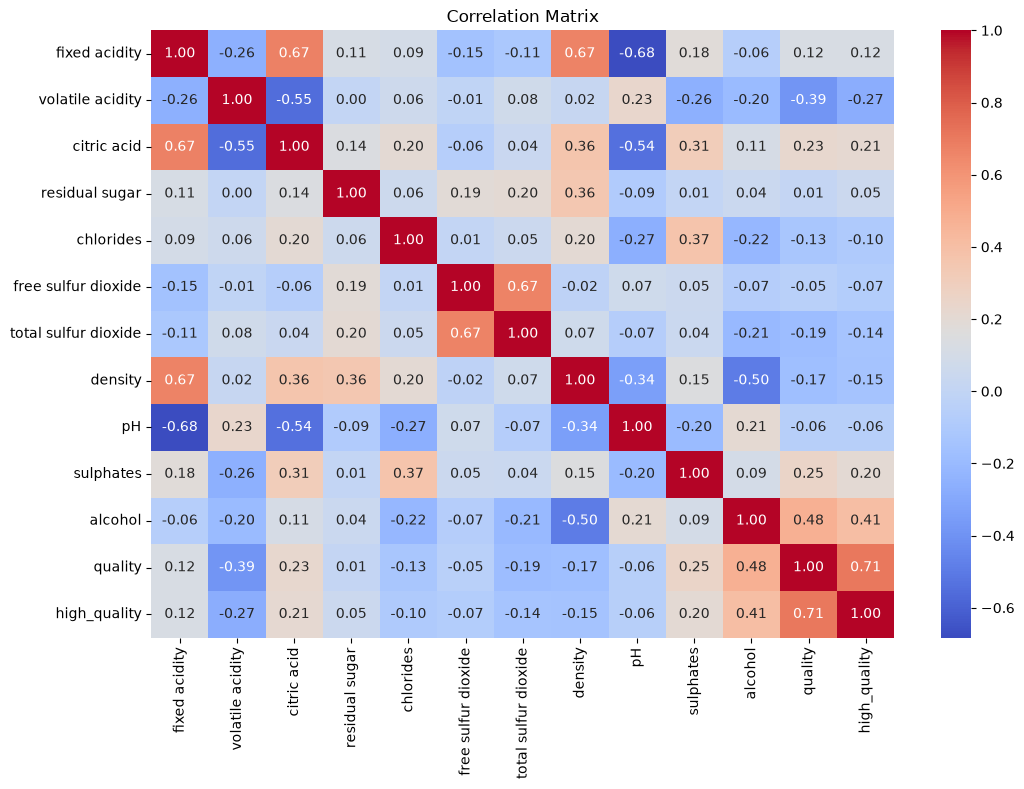

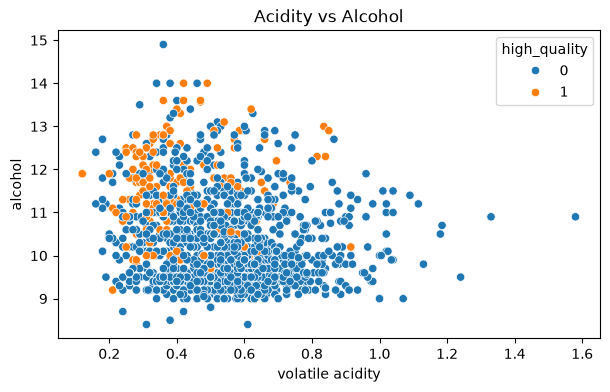

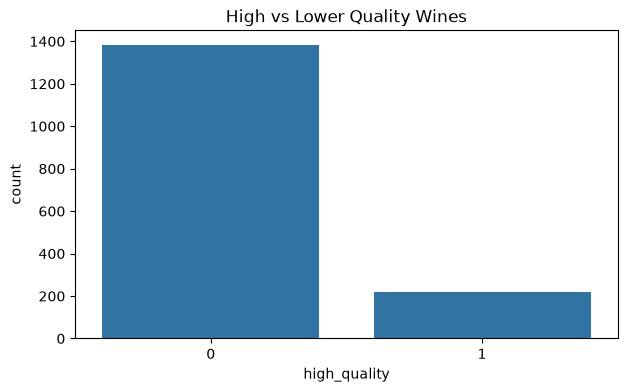

In [11]:
# Chart 1: Quality distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="quality")
plt.title("Wine Quality Distribution")
plt.show()

# Chart 2: Alcohol distribution
plt.figure(figsize=(7, 4))
sns.histplot(df["alcohol"], kde=True)
plt.title("Alcohol Distribution")
plt.show()

# Chart 3: Alcohol vs Quality
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="quality", y="alcohol")
plt.title("Alcohol vs Wine Quality")
plt.show()

# Chart 4: Correlation heatmap
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(), annot=True,
            cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

# Chart 5: Acidity vs Alcohol
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="volatile acidity",
                y="alcohol", hue="high_quality")
plt.title("Acidity vs Alcohol")
plt.show()

# Chart 6: Classification distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="high_quality")
plt.title("High vs Lower Quality Wines")
plt.show()

### EDA Summary

The data was reviewed for missing and duplicate data. Duplicate records were kept in case the same measurements are the same wine types.

A binary indicator was formed where quality scored 7 or above wine as a high quality (1) and the rest of the wine as a lower quality (0).

To explore the features distributions and decorrelations, and relationships with wine quality, Exploratory Data Analysis (EDA) was carried out.

## Modeling<a class="anchor" id="modeling"></a>



Logistic Regression, Decision Tree and Random Forest were chosen as the machine learning algorithms.

Logistic Regression takes care of a baseline model, Decision Tree takes care of Nonlinear relationship and Random Forest takes care of combination of multiple decision trees, which increases the prediction power.

The data are split into 80% training and 20% test. Logistic Regression is standardised with the help of the StandardScaler.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Separate features and target
X = df.drop(columns=["quality", "high_quality"])
y = df["high_quality"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Define models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}

# Train models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "- Training completed")

Logistic Regression - Training completed
Decision Tree - Training completed
Random Forest - Training completed


## Evaluation<a class="anchor" id="evaluation"></a>



Three models are tested using the accuracy, precision, recall and F1 score. The F1 score is used as the main score since the score quality classes are imbalanced.

Errors in classification are investigated by examining a confusion matrix and model performance is compared.

In [13]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

results = []

for name, model in models.items():
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0)
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.894,0.696,0.372,0.485
1,Decision Tree,0.919,0.730,0.628,0.675
2,Random Forest,0.944,0.931,0.628,0.750


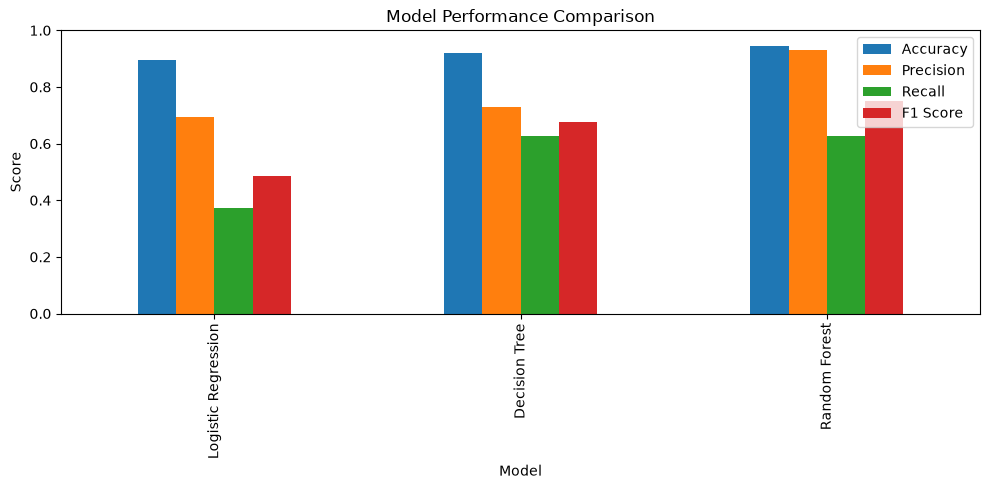

Best Model: Random Forest
              precision    recall  f1-score   support

           0       0.95      0.99      0.97       277
           1       0.93      0.63      0.75        43

    accuracy                           0.94       320
   macro avg       0.94      0.81      0.86       320
weighted avg       0.94      0.94      0.94       320



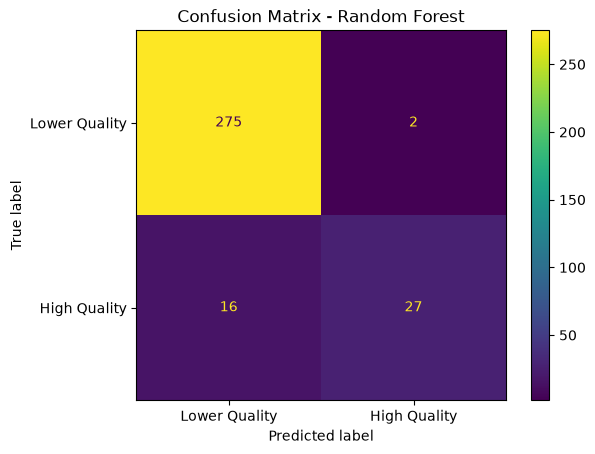

In [14]:
# Compare model performance
results_df.set_index("Model").plot(
    kind="bar", figsize=(10, 5)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# Select best model
best_name = results_df.loc[
    results_df["F1 Score"].idxmax(), "Model"
]

best_model = models[best_name]
pred = best_model.predict(X_test)

print("Best Model:", best_name)
print(classification_report(y_test, pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred,
    display_labels=["Lower Quality", "High Quality"]
)
plt.title("Confusion Matrix - " + best_name)
plt.show()

### Conclusion

In this experiment Logistic Regression, Decision Tree and Random Forest were tested for classifying the Red wine quality.

The models were assessed based on various performance measures and the most optimal model has selected based on the F1 score.

The results presented here prove the potential of machine learning for prediction of wine quality. Further work can be done using cross validation and optimization of the hyper parameters.

## References<a class="anchor" id="references"></a>


Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems, 47*(4), 547–553. https://doi.org/10.1016/j.dss.2009.05.016

Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html

UCI Machine Learning Repository. (n.d.). *Wine Quality dataset*. University of California, Irvine. https://archive.ics.uci.edu/dataset/186/wine+quality


**Disclaimer!**

*This notebook was prepared by **Paulo Henrique Abdala Araujo** as a term project. The notebook is available for educational purposes only. There is no guarantee on the correctness of the content provided, as it is student work.*

In [1]:
!jupyter nbconvert --to webpdf --allow-chromium-download "AIT620_Final_Wine_Quality2.ipynb"

[NbConvertApp] Converting notebook AIT620_Final_Wine_Quality2.ipynb to webpdf
[NbConvertApp] WARNING | Alternative text is missing on 8 image(s).
[NbConvertApp] Building PDF
185.8 MiB [                    ] 0% 0.0s185.8 MiB [                    ] 0% 425.2s185.8 MiB [                    ] 0% 312.6s185.8 MiB [                    ] 0% 292.0s185.8 MiB [                    ] 0% 273.8s185.8 MiB [                    ] 0% 254.4s185.8 MiB [                    ] 0% 231.2s185.8 MiB [                    ] 0% 201.5s185.8 MiB [                    ] 0% 176.7s185.8 MiB [                    ] 0% 151.3s185.8 MiB [                    ] 0% 124.4s185.8 MiB [                    ] 0% 109.5s185.8 MiB [                    ] 0% 90.3s185.8 MiB [                    ] 0% 70.2s185.8 MiB [                    ] 0% 61.2s185.8 MiB [                    ] 0% 52.0s185.8 MiB [                    ] 0% 43.1s185.8 MiB [                    ] 0% 36.6s185.8 MiB [                    ] 0% 33.7s185.8 MiB [                    ] 1% 2